In [1]:
import pandas as pd

In [2]:
import statsmodels

print(statsmodels.__version__)

0.15.0


In [3]:
df = pd.read_csv("../data/raw/PJME_hourly.csv")

In [6]:
df.head()

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


In [7]:
df["Datetime"] = pd.to_datetime(df["Datetime"])

In [8]:
df = df.set_index("Datetime")

In [9]:
df = df.sort_index()

In [10]:
df.head()

,PJME_MW
Datetime,
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0
2002-01-01 04:00:00,27899.0
2002-01-01 05:00:00,28057.0


In [11]:
df.shape

(145366, 1)

In [12]:
print(df.index.min())
print(df.index.max())

2002-01-01 01:00:00
2018-08-03 00:00:00


In [13]:
df.index.duplicated().sum()

np.int64(4)

In [14]:
expected_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq="h")
print("Expected timestamps if no gaps:", len(expected_range))
print("Actual timestamps we have:", len(df.index))

Expected timestamps if no gaps: 145392
Actual timestamps we have: 145366


In [15]:
df[df.index.duplicated(keep=False)]

,PJME_MW
Datetime,
2014-11-02 02:00:00,23755.0
2014-11-02 02:00:00,22935.0
2015-11-01 02:00:00,21567.0
2015-11-01 02:00:00,21171.0
2016-11-06 02:00:00,20795.0
2016-11-06 02:00:00,21692.0
2017-11-05 02:00:00,21236.0
2017-11-05 02:00:00,20666.0


In [16]:
df = df.groupby(df.index).mean()

In [17]:
df.index.duplicated().sum()

np.int64(0)

In [18]:
full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq="h")
df = df.reindex(full_range)

In [19]:
df["PJME_MW"].isna().sum()

np.int64(30)

In [20]:
df["PJME_MW"] = df["PJME_MW"].interpolate(method="linear")

In [21]:
df["PJME_MW"].isna().sum()

np.int64(0)

In [22]:
df.shape

(145392, 1)

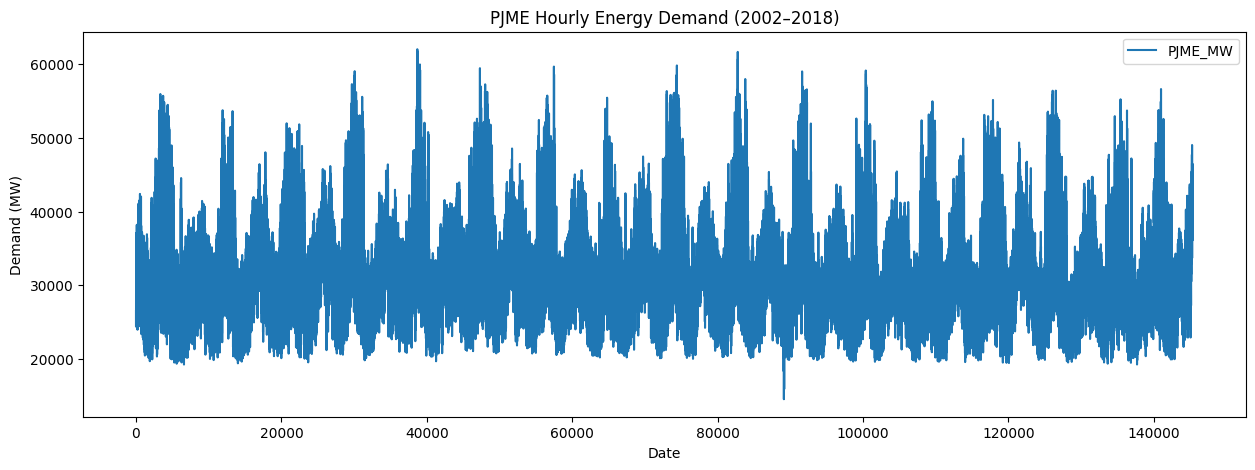

In [4]:
import matplotlib.pyplot as plt

df.plot(figsize=(15, 5))
plt.title("PJME Hourly Energy Demand (2002–2018)")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.show()

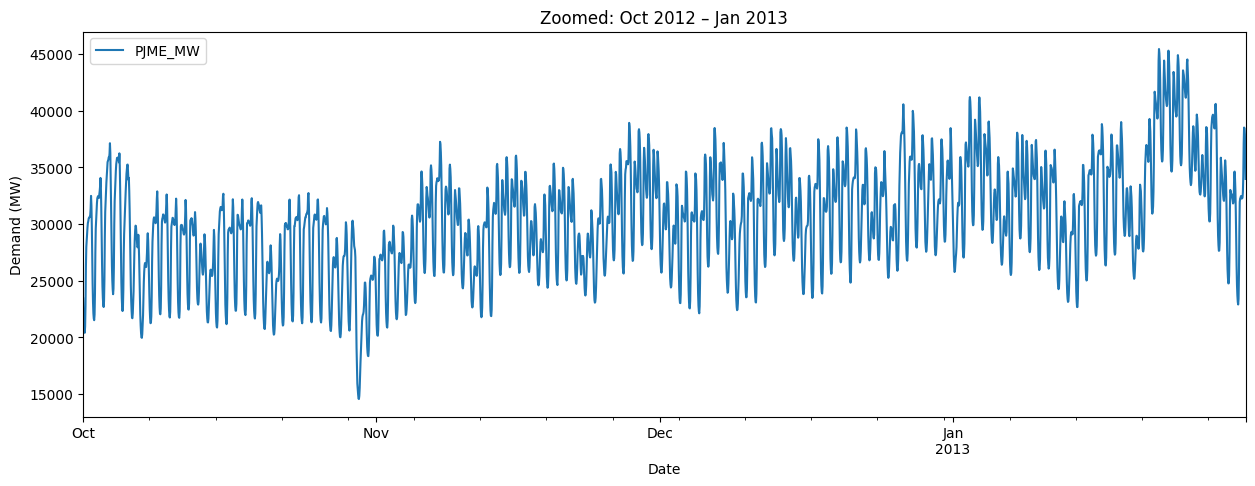

In [ ]:
df.loc["2012-10-01":"2013-01-31"].plot(figsize=(15, 5))
plt.title("Zoomed: Oct 2012 – Jan 2013")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.show()

In [ ]:
df.loc["2012-10-01":"2013-01-31"].sort_values("PJME_MW").head(10)

,PJME_MW
2012-10-30 04:00:00,14544.0
2012-10-30 03:00:00,14586.0
2012-10-30 05:00:00,14821.0
2012-10-30 02:00:00,14955.0
2012-10-30 01:00:00,15390.0
2012-10-30 06:00:00,15526.0
2012-10-30 00:00:00,15919.0
2012-10-30 07:00:00,16688.0
2012-10-29 23:00:00,17422.0
2012-10-30 08:00:00,17734.0


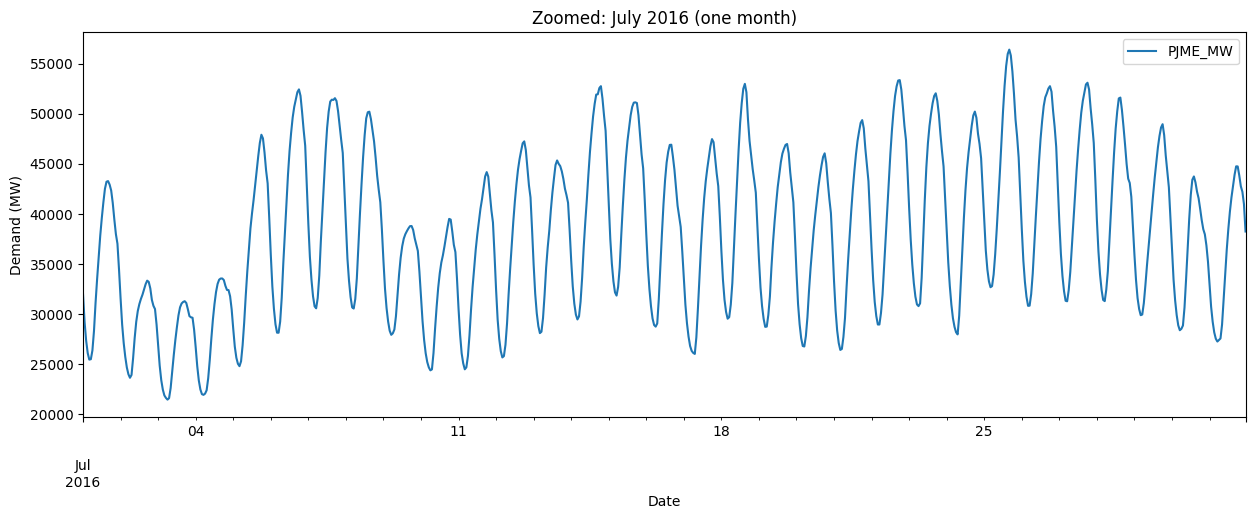

In [ ]:
df.loc["2016-07-01":"2016-07-31"].plot(figsize=(15, 5))
plt.title("Zoomed: July 2016 (one month)")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.show()

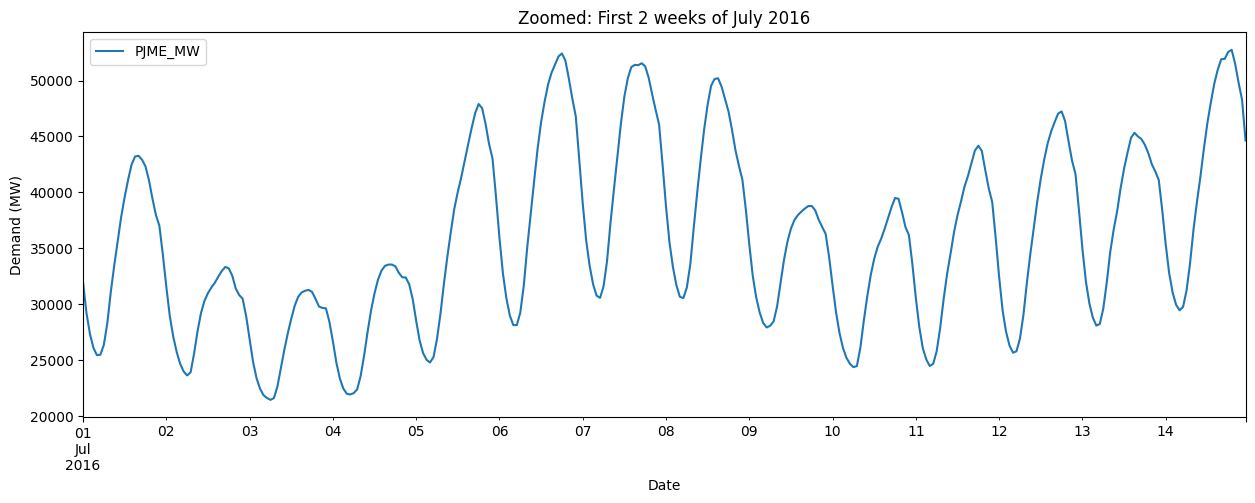

In [ ]:
df.loc["2016-07-01":"2016-07-14"].plot(figsize=(15, 5))
plt.title("Zoomed: First 2 weeks of July 2016")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.show()

In [ ]:
df["day_of_week"] = df.index.day_name()
df.loc["2016-07-01":"2016-07-14", "day_of_week"].unique()

array(['Friday', 'Saturday', 'Sunday', 'Monday', 'Tuesday', 'Wednesday',
       'Thursday'], dtype=object)

In [ ]:
df["is_weekend"] = df.index.dayofweek >= 5  # Saturday=5, Sunday=6

df.groupby("is_weekend")["PJME_MW"].mean()

is_weekend
False    32996.116316
True     29784.365499
Name: PJME_MW, dtype: float64

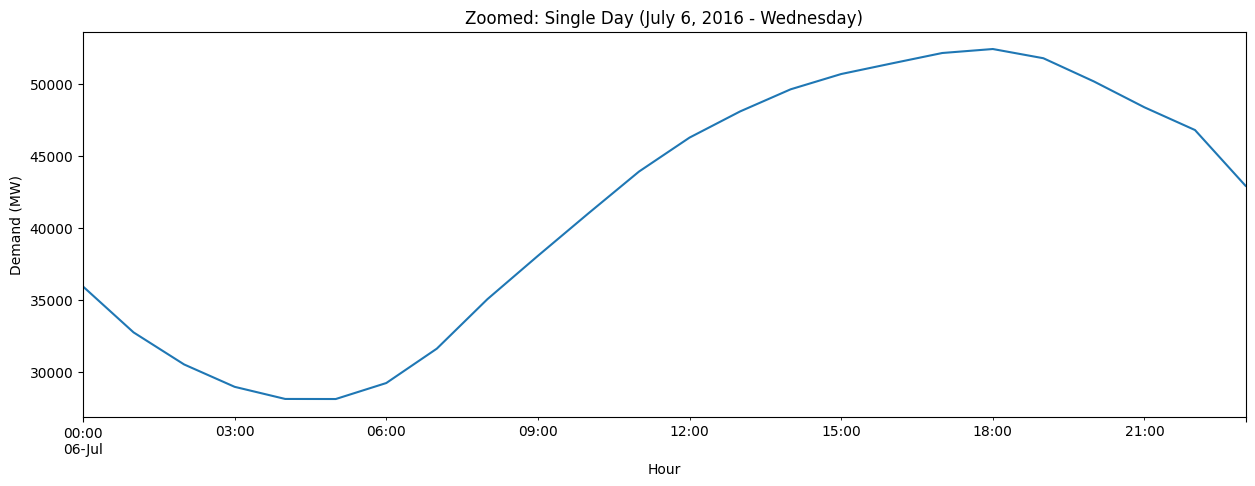

In [ ]:
df.loc["2016-07-06":"2016-07-06", "PJME_MW"].plot(figsize=(15, 5))
plt.title("Zoomed: Single Day (July 6, 2016 - Wednesday)")
plt.xlabel("Hour")
plt.ylabel("Demand (MW)")
plt.show()

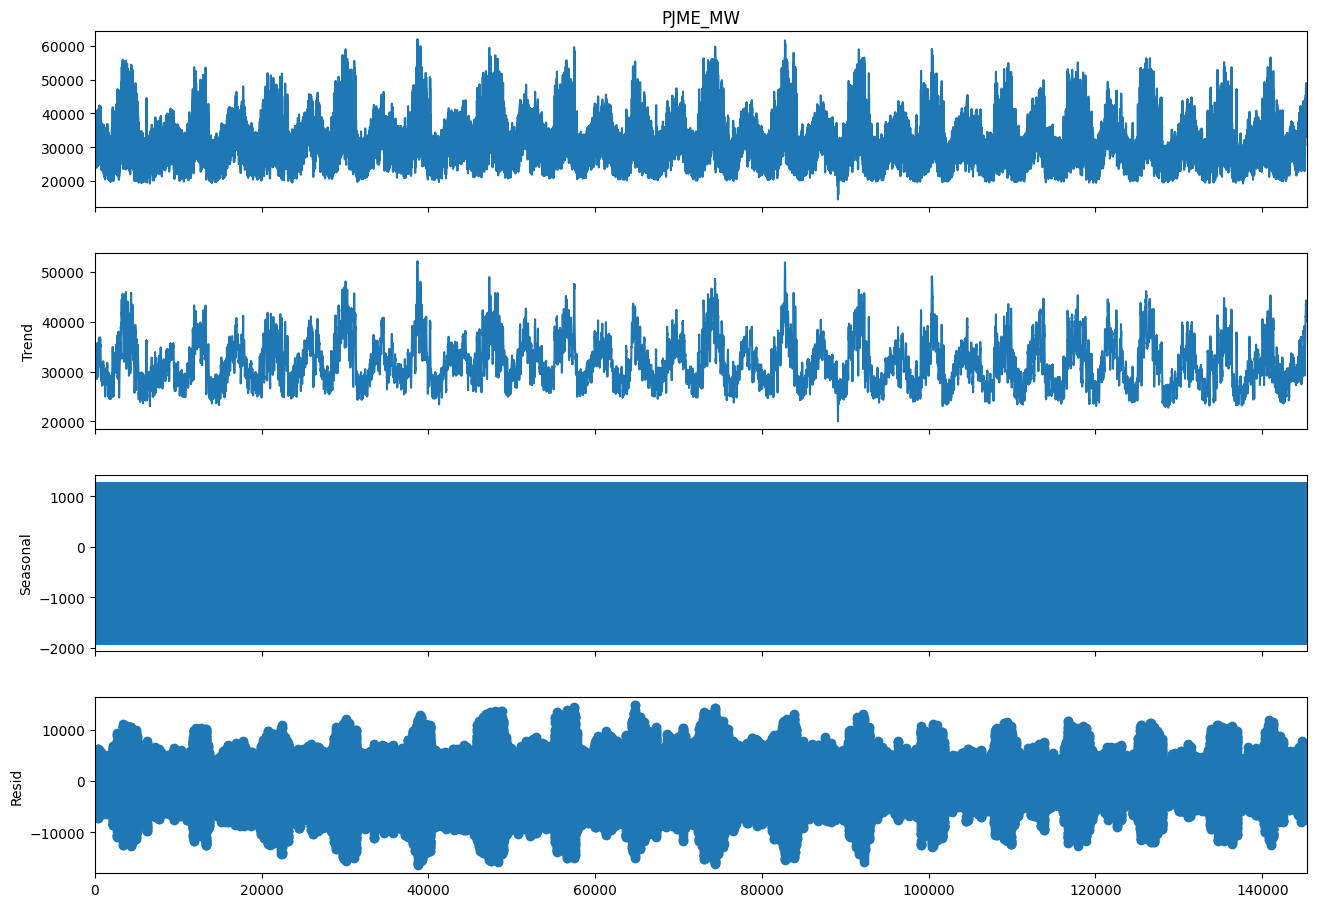

In [5]:

from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(df["PJME_MW"], model="additive", period=24)

fig = decomposition.plot()
fig.set_size_inches(15, 10)
plt.show()

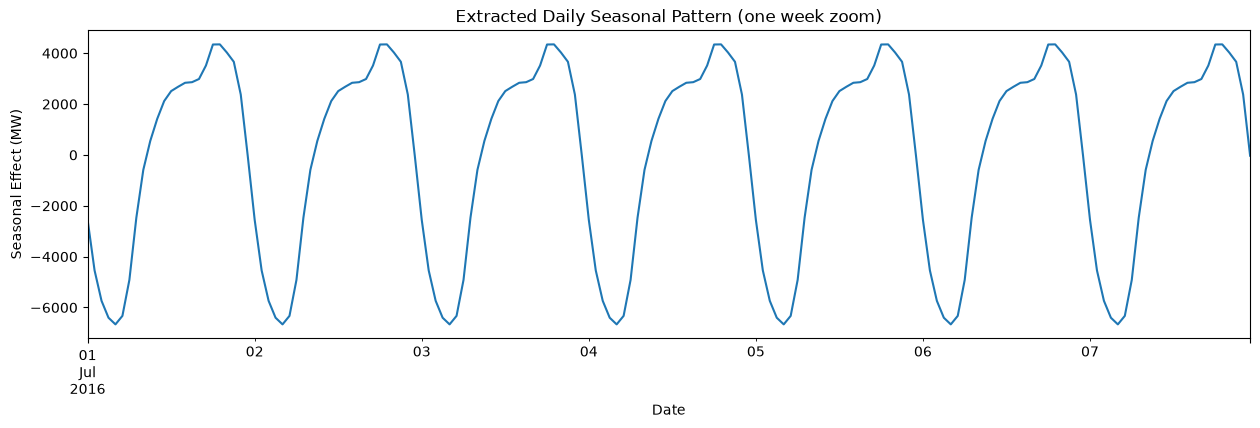

In [ ]:
decomposition.seasonal["2016-07-01":"2016-07-07"].plot(figsize=(15, 4))
plt.title("Extracted Daily Seasonal Pattern (one week zoom)")
plt.xlabel("Date")
plt.ylabel("Seasonal Effect (MW)")
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

# Test 1: raw series
result_raw = adfuller(df["PJME_MW"])
print("Raw series ADF test:")
print(f"  ADF Statistic: {result_raw[0]:.4f}")
print(f"  p-value: {result_raw[1]:.4f}")

# Test 2: residual (drop NaN rows first - decomposition can't compute 
# residual for the first/last few points due to the rolling window)
resid_clean = decomposition.resid.dropna()
result_resid = adfuller(resid_clean)
print("\nResidual (daily-decomposed) ADF test:")
print(f"  ADF Statistic: {result_resid[0]:.4f}")
print(f"  p-value: {result_resid[1]:.4f}")

Raw series ADF test:
  ADF Statistic: -19.9646
  p-value: 0.0000

Residual (daily-decomposed) ADF test:
  ADF Statistic: -70.0864
  p-value: 0.0000


In [ ]:
from statsmodels.tsa.stattools import kpss

result_kpss_raw = kpss(df["PJME_MW"], regression="c", nlags="auto")
print("Raw series KPSS test:")
print(f"  KPSS Statistic: {result_kpss_raw[0]:.4f}")
print(f"  p-value: {result_kpss_raw[1]:.4f}")

Raw series KPSS test:
  KPSS Statistic: 1.3027
  p-value: 0.0100


C:\Users\hp\AppData\Local\Temp\ipykernel_10728\1016866796.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  result_kpss_raw = kpss(df["PJME_MW"], regression="c", nlags="auto")


In [7]:
df["seasonal_diff_24"] = df["PJME_MW"].diff(24)

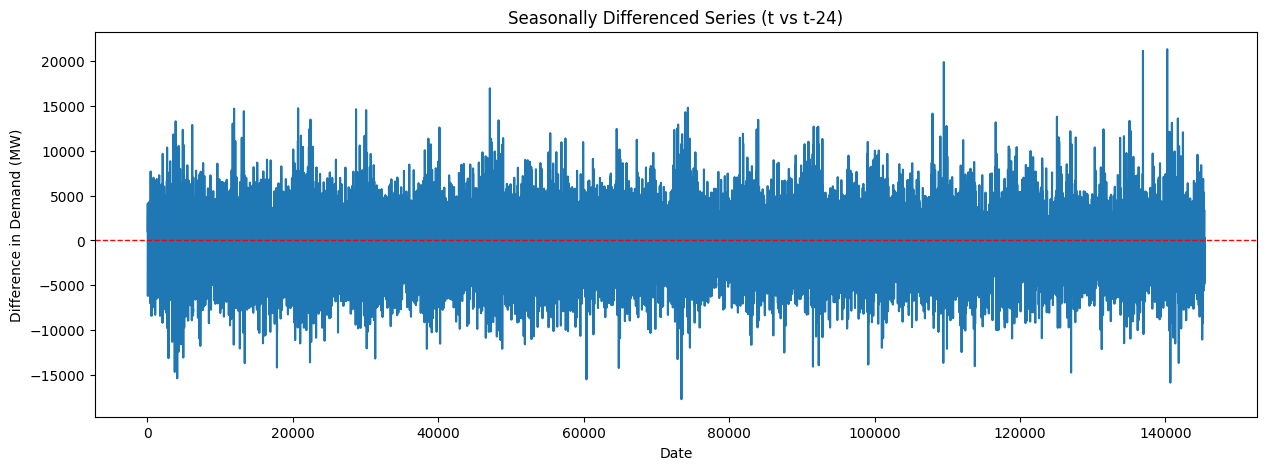

In [8]:
df["seasonal_diff_24"].plot(figsize=(15, 5))
plt.title("Seasonally Differenced Series (t vs t-24)")
plt.xlabel("Date")
plt.ylabel("Difference in Demand (MW)")
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.show()

In [9]:
from statsmodels.tsa.stattools import adfuller, kpss

diff_clean = df["seasonal_diff_24"].dropna()

result_adf = adfuller(diff_clean)
print("Seasonally Differenced - ADF test:")
print(f"  ADF Statistic: {result_adf[0]:.4f}")
print(f"  p-value: {result_adf[1]:.4f}")

result_kpss = kpss(diff_clean, regression="c", nlags="auto")
print("\nSeasonally Differenced - KPSS test:")
print(f"  KPSS Statistic: {result_kpss[0]:.4f}")
print(f"  p-value: {result_kpss[1]:.4f}")

Seasonally Differenced - ADF test:
  ADF Statistic: -46.9667
  p-value: 0.0000

Seasonally Differenced - KPSS test:
  KPSS Statistic: 0.0035
  p-value: 0.1000


C:\Users\hp\AppData\Local\Temp\ipykernel_18620\211764272.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_adf = adfuller(diff_clean)
C:\Users\hp\AppData\Local\Temp\ipykernel_18620\211764272.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  result_kpss = kpss(diff_clean, regression="c", nlags="auto")
C:\Users\hp\AppData\Local\Temp\ipykernel_18620\211764272.py:10: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 

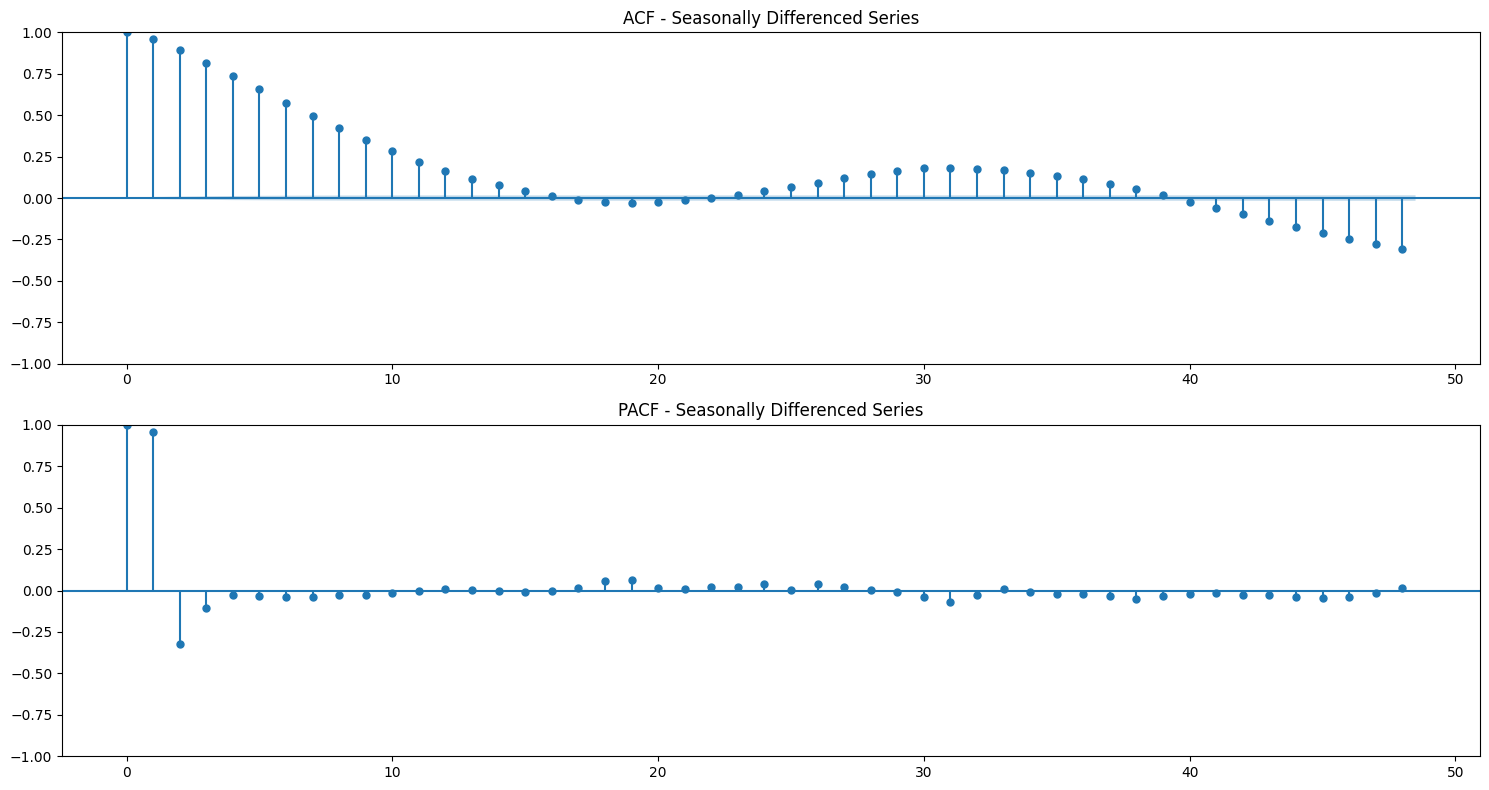

In [10]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(15, 8))

plot_acf(diff_clean, lags=48, ax=axes[0])
axes[0].set_title("ACF - Seasonally Differenced Series")

plot_pacf(diff_clean, lags=48, ax=axes[1], method="ywm")
axes[1].set_title("PACF - Seasonally Differenced Series")

plt.tight_layout()
plt.show()

Name: statsmodels
Version: 0.15.0
Summary: Statistical computations and models for Python
Home-page: 
Author: 
Author-email: 
License: 
Location: c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages
Requires: formulaic, numpy, packaging, pandas, patsy, scipy
Required-by: 


0.15.0
c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\__init__.py
